<a href="https://colab.research.google.com/github/awinarko-hue/Latihan/blob/main/DataSains/Multi_Horizon_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Sel 1: Instalasi Library & Konfigurasi Awal**

In [1]:
# ==============================================================================
# SEL 1: INSTALASI LIBRARY & IMPORT MODUL
# ==============================================================================
!pip install -q xgboost lightgbm shap statsmodels scikit-learn tensorflow

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

import xgboost as xgb
import lightgbm as lgb
import shap

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from google.colab import drive
drive.mount('/content/drive')

# Set random seed untuk reprodusibilitas eksperimen
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

Mounted at /content/drive


# **Sel 2: Blok 1 (RM 1) — Akuisisi Data, Pembersihan Sensor, & EDA (ACF/PACF)**
Pastikan kedua file (lab electrical csv komplit okt 25 26.csv dan lab wiredline cvs komplit.csv) sudah diunggah ke panel Files di sebelah kiri Google Colab. Kode ini memungkinkan Anda memilih apakah menggunakan kolom Terkoreksi atau nilai mentah (USE_CORRECTED = True).

=== AUDIT DATA: Electrical Safety ===
Total baris awal        : 7794
Duplikasi timestamp     : 10 baris (dihapus)
Sensor error (nilai <=5): 1 baris (diubah ke NaN untuk diimputasi)
Rentang waktu           : 2025-10-27 16:00:00 s.d. 2026-10-08 10:00:00 (8299 jam grid penuh)
Total missing hours     : 516 jam (6.22%)

=== AUDIT DATA: Wiredline & Laser Safety ===
Total baris awal        : 7142
Duplikasi timestamp     : 2 baris (dihapus)
Sensor error (nilai <=5): 0 baris (diubah ke NaN untuk diimputasi)
Rentang waktu           : 2025-10-27 16:00:00 s.d. 2026-10-08 10:00:00 (8299 jam grid penuh)
Total missing hours     : 1159 jam (13.97%)



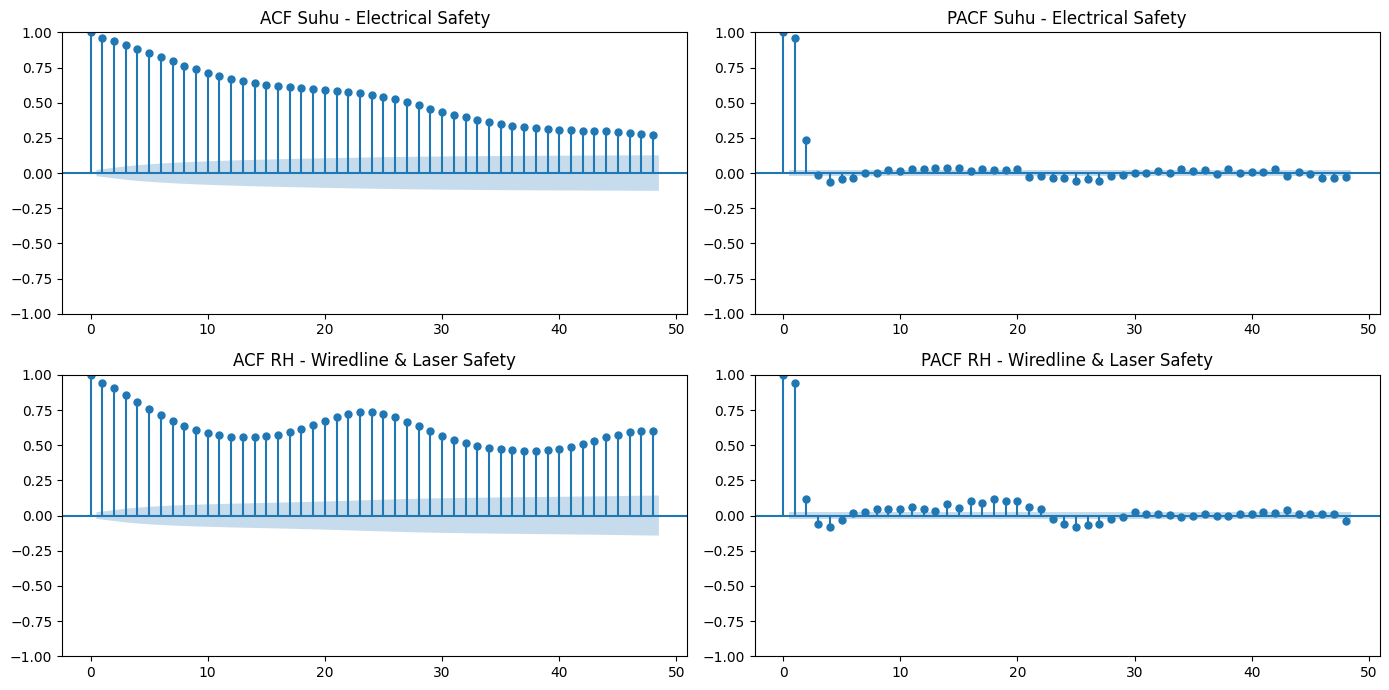

In [2]:
# ==============================================================================
# SEL 2: BLOK 1 (RM 1) - LOAD DATA, KUALITAS DATA, & ANALISIS ACF/PACF
# ==============================================================================
FILE_ELEC = '/content/drive/MyDrive/Kuliah/Kuliah/Project5/lab electrical csv komplit okt 25 26.csv'
FILE_WIRE = '/content/drive/MyDrive/Kuliah/Kuliah/Project5/lab wiredline cvs komplit.csv'

# Gunakan kolom 'Suhu Terkoreksi' & 'Kelembapan Terkoreksi' (True) atau mentah (False)
USE_CORRECTED = True
COL_SUHU = 'Suhu Terkoreksi' if USE_CORRECTED else 'Suhu'
COL_RH   = 'Kelembapan Terkoreksi' if USE_CORRECTED else 'Kelembapan'

def load_and_audit_data(filepath, room_label):
    df = pd.read_csv(filepath)

    # 1. Parsing Tanggal dan Jam (mengubah format ' 10.00.00' menjadi '10:00:00')
    dt_str = (
        df['Tanggal'].astype(str).str.strip() + ' ' +
        df['Jam'].astype(str).str.strip().str.replace('.', ':', regex=False)
    )
    df['Datetime'] = pd.to_datetime(dt_str, dayfirst=True, errors='coerce')

    # 2. Urutkan secara kronologis (data asli terurut mundur dari 2026 ke 2025)
    df = df.sort_values('Datetime').reset_index(drop=True)

    # 3. Audit Kualitas Data Awal
    total_raw = len(df)
    dup_count = df['Datetime'].duplicated().sum()
    df = df.drop_duplicates(subset=['Datetime'], keep='first')

    # Deteksi sensor error (nilai Suhu atau RH <= 5, misal 0.0 atau -5.4)
    sensor_err = (df['Suhu'] <= 5) | (df['Kelembapan'] <= 5)
    err_count = sensor_err.sum()
    df.loc[sensor_err, ['Suhu', 'Kelembapan', 'Suhu Terkoreksi', 'Kelembapan Terkoreksi']] = np.nan

    # 4. Resampling ke grid 1 jam penuh untuk mendeteksi missing timestamps
    df = df.set_index('Datetime').resample('1h').asfreq()
    missing_hours = df[COL_SUHU].isna().sum()

    df['Ruangan'] = room_label
    df['temp'] = df[COL_SUHU]
    df['rh']   = df[COL_RH]

    print(f"=== AUDIT DATA: {room_label} ===")
    print(f"Total baris awal        : {total_raw}")
    print(f"Duplikasi timestamp     : {dup_count} baris (dihapus)")
    print(f"Sensor error (nilai <=5): {err_count} baris (diubah ke NaN untuk diimputasi)")
    print(f"Rentang waktu           : {df.index.min()} s.d. {df.index.max()} ({len(df)} jam grid penuh)")
    print(f"Total missing hours     : {missing_hours} jam ({missing_hours/len(df)*100:.2f}%)\n")

    return df[['Ruangan', 'temp', 'rh']]

df_elec_raw = load_and_audit_data(FILE_ELEC, 'Electrical Safety')
df_wire_raw = load_and_audit_data(FILE_WIRE, 'Wiredline & Laser Safety')

# Visualisasi ACF dan PACF untuk dasar penentuan Lag Features (RM 1)
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(df_elec_raw['temp'].dropna(), lags=48, ax=axes[0, 0], title='ACF Suhu - Electrical Safety')
plot_pacf(df_elec_raw['temp'].dropna(), lags=48, ax=axes[0, 1], title='PACF Suhu - Electrical Safety')
plot_acf(df_wire_raw['rh'].dropna(), lags=48, ax=axes[1, 0], title='ACF RH - Wiredline & Laser Safety')
plot_pacf(df_wire_raw['rh'].dropna(), lags=48, ax=axes[1, 1], title='PACF RH - Wiredline & Laser Safety')
plt.tight_layout()
plt.show()

# **Sel 3: Blok 2 (RM 2) — Pra-Pemrosesan Anti-Leakage, Feature Engineering, & Temporal Split (70/15/15)**
Kode di bawah ini mengimplementasikan forward fill / interpolasi masa lalu (tanpa membocorkan data masa depan), pembentukan fitur lag ($1, 2, 3, 6, 12, 24$ jam), rolling statistics ($3, 6, 12, 24$ jam), fitur interaksi termodinamika, serta cyclical time encoding.   

In [3]:
# ==============================================================================
# SEL 3: BLOK 2 (RM 2) - FEATURE ENGINEERING & TEMPORAL SPLIT (70/15/15)
# ==============================================================================
# Ambang batas operasional ISO/IEC 17025:2017 di IDTH
TEMP_MIN, TEMP_MAX = 20.0, 26.0
RH_MIN, RH_MAX     = 50.0, 70.0
HORIZONS           = [1, 3, 6]

def is_deviation(temp_val, rh_val):
    """Mengembalikan 1 jika Suhu di luar [20, 26] ATAU RH di luar [50, 70], selain itu 0."""
    return ((temp_val < TEMP_MIN) | (temp_val > TEMP_MAX) |
            (rh_val < RH_MIN) | (rh_val > RH_MAX)).astype(int)

def build_features(df_room, room_id=0):
    df = df_room.copy()

    # 1. Imputasi kausal (hanya memakai nilai masa lalu: forward fill lalu linear terbatas)
    df['temp'] = df['temp'].ffill().bfill()
    df['rh']   = df['rh'].ffill().bfill()

    # 2. Lag Features (berdasarkan evaluasi ACF/PACF harian 24 jam)
    lags = [1, 2, 3, 6, 12, 24]
    for l in lags:
        df[f'temp_lag_{l}'] = df['temp'].shift(l)
        df[f'rh_lag_{l}']   = df['rh'].shift(l)

    # 3. Rolling Statistics (menggunakan data s.d. waktu t)
    windows = [3, 6, 12, 24]
    for w in windows:
        df[f'temp_roll_mean_{w}'] = df['temp'].rolling(window=w).mean()
        df[f'temp_roll_std_{w}']  = df['temp'].rolling(window=w).std()
        df[f'temp_roll_min_{w}']  = df['temp'].rolling(window=w).min()
        df[f'temp_roll_max_{w}']  = df['temp'].rolling(window=w).max()

        df[f'rh_roll_mean_{w}']   = df['rh'].rolling(window=w).mean()
        df[f'rh_roll_std_{w}']    = df['rh'].rolling(window=w).std()
        df[f'rh_roll_min_{w}']    = df['rh'].rolling(window=w).min()
        df[f'rh_roll_max_{w}']    = df['rh'].rolling(window=w).max()

    # 4. Time-based & Cyclical Features (jam, hari, akhir pekan, bulan)
    df['hour']       = df.index.hour
    df['dayofweek']  = df.index.dayofweek
    df['is_weekend'] = (df.index.dayofweek >= 5).astype(int)
    df['month']      = df.index.month

    df['hour_sin']   = np.sin(2 * np.pi * df['hour'] / 24.0)
    df['hour_cos']   = np.cos(2 * np.pi * df['hour'] / 24.0)
    df['month_sin']  = np.sin(2 * np.pi * df['month'] / 12.0)
    df['month_cos']  = np.cos(2 * np.pi * df['month'] / 12.0)

    # 5. Interaction Features (aproksimasi titik embun / Dew Point & rasio T-RH)
    df['temp_rh_interaction'] = df['temp'] * df['rh']
    df['dew_point_approx']    = df['temp'] - ((100.0 - df['rh']) / 5.0)
    df['current_dev_status']  = is_deviation(df['temp'], df['rh'])
    df['room_id']             = room_id

    # 6. Pembentukan Target Multi-Horizon (t+1, t+3, t+6)
    for h in HORIZONS:
        df[f'target_temp_h{h}'] = df['temp'].shift(-h)
        df[f'target_rh_h{h}']   = df['rh'].shift(-h)
        df[f'target_dev_h{h}']  = is_deviation(df[f'target_temp_h{h}'], df[f'target_rh_h{h}'])

    df = df.dropna().copy()
    return df

df_elec_feat = build_features(df_elec_raw, room_id=0)
df_wire_feat = build_features(df_wire_raw, room_id=1)

# Daftar kolom fitur input (X)
FEATURE_COLS = [c for c in df_elec_feat.columns
                if not c.startswith('target_') and c not in ['Ruangan', 'room_id']]

def temporal_split_70_15_15(df):
    """Membagi dataset secara berurutan waktu: 70% Train, 15% Validation, 15% Test."""
    n = len(df)
    i_train = int(n * 0.70)
    i_val   = int(n * 0.85)
    return df.iloc[:i_train].copy(), df.iloc[i_train:i_val].copy(), df.iloc[i_val:].copy()

elec_train, elec_val, elec_test = temporal_split_70_15_15(df_elec_feat)
wire_train, wire_val, wire_test = temporal_split_70_15_15(df_wire_feat)

print(f"Fitur Input ({len(FEATURE_COLS)} fitur): {FEATURE_COLS[:6]} ...")
print(f"Electrical Split -> Train: {len(elec_train)}, Val: {len(elec_val)}, Test: {len(elec_test)}")
print(f"Wiredline Split  -> Train: {len(wire_train)}, Val: {len(wire_val)}, Test: {len(wire_test)}")

Fitur Input (57 fitur): ['temp', 'rh', 'temp_lag_1', 'rh_lag_1', 'temp_lag_2', 'rh_lag_2'] ...
Electrical Split -> Train: 5788, Val: 1240, Test: 1241
Wiredline Split  -> Train: 5788, Val: 1240, Test: 1241


# **Sel 4: Blok 3 (RM 2 & RM 3) — Fungsi Pemodelan 5 Algoritma, Baseline, & Metrik Evaluasi 3 Dimensi**
Bagian ini mendefinisikan pipeline pelatihan untuk kelima algoritma (Random Forest, SVR, XGBoost, LightGBM, LSTM) beserta pembanding Baseline Persistence ($\hat{y}_{t+h} = y_t$) dan Majority Class. Setiap model memprediksi nilai suhu dan kelembaban relatif terlebih dahulu, kemudian ditransformasikan menjadi status deviasi untuk dihitung metrik regresi, klasifikasi, serta Early Warning (False Alarm Rate dan Effective Lead Time).

In [4]:
# ==============================================================================
# SEL 4: BLOK 3 (RM 2 & RM 3) - ENGINE PEMODELAN & METRIK EVALUASI
# ==============================================================================
def calc_regression_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100.0
    return {'RMSE': rmse, 'MAE': mae, 'R2': r2, 'MAPE(%)': mape}

def calc_classification_and_ews_metrics(y_true_dev, y_pred_dev, y_Continuous_score, horizon):
    acc  = accuracy_score(y_true_dev, y_pred_dev)
    prec = precision_score(y_true_dev, y_pred_dev, zero_division=0)
    rec  = recall_score(y_true_dev, y_pred_dev, zero_division=0)
    f1   = f1_score(y_true_dev, y_pred_dev, zero_division=0)

    # ROC-AUC (jika terdapat 2 kelas di test set)
    if len(np.unique(y_true_dev)) > 1:
        roc_auc = roc_auc_score(y_true_dev, y_Continuous_score)
    else:
        roc_auc = np.nan

    # False Alarm Rate (FAR) = FP / (FP + TN) sesuai Persamaan (2.21)
    tn = np.sum((y_true_dev == 0) & (y_pred_dev == 0))
    fp = np.sum((y_true_dev == 0) & (y_pred_dev == 1))
    tp = np.sum((y_true_dev == 1) & (y_pred_dev == 1))
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    # Effective Mean Lead Time (jam): rata-rata waktu antisipasi pada kejadian deviasi yang terdeteksi
    # Jika pada horizon h model mendeteksi True Positive, maka peringatan keluar h jam sebelum kejadian
    effective_lead_time = horizon * rec

    return {
        'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1,
        'ROC_AUC': roc_auc, 'FAR': far, 'Effective_Lead_Time(Jam)': effective_lead_time
    }

def compute_deviation_risk_score(pred_temp, pred_rh):
    """Menghitung skor kedekatan/pelanggaran terhadap ambang batas ISO 17025 untuk ROC-AUC."""
    temp_violation = np.maximum(0, TEMP_MIN - pred_temp) + np.maximum(0, pred_temp - TEMP_MAX)
    rh_violation   = np.maximum(0, RH_MIN - pred_rh) + np.maximum(0, pred_rh - RH_MAX)
    # Jarak normalisasi dari titik tengah ideal (23°C dan 60% RH)
    norm_dist = np.abs(pred_temp - 23.0) / 3.0 + np.abs(pred_rh - 60.0) / 10.0
    return norm_dist + (temp_violation + rh_violation) * 10.0

def build_and_train_lstm(X_tr, y_tr, X_va, y_va):
    """Membangun model LSTM dengan EarlyStopping pada Validation Set."""
    X_tr_3d = X_tr.reshape((X_tr.shape[0], 1, X_tr.shape[1]))
    X_va_3d = X_va.reshape((X_va.shape[0], 1, X_va.shape[1]))

    model = Sequential([
        LSTM(64, activation='tanh', input_shape=(1, X_tr.shape[1]), return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003), loss='mse')
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)
    model.fit(X_tr_3d, y_tr, validation_data=(X_va_3d, y_va),
              epochs=35, batch_size=64, callbacks=[es], verbose=0)
    return model

def run_experiment_pipeline(train_df, val_df, test_df, feature_cols, scenario_name="S1", include_lstm=True):
    """
    Melatih dan mengevaluasi Baseline + 5 Algoritma ML pada horizon t+1, t+3, t+6.
    Normalisasi di-fit HANYA pada train_df untuk mencegah data leakage.
    """
    scaler = StandardScaler()
    X_train_raw = train_df[feature_cols].values
    X_val_raw   = val_df[feature_cols].values
    X_test_raw  = test_df[feature_cols].values

    X_train_sc = scaler.fit_transform(X_train_raw)
    X_val_sc   = scaler.transform(X_val_raw)
    X_test_sc  = scaler.transform(X_test_raw)

    results = []
    trained_artifacts = {}

    for h in HORIZONS:
        print(f"  -> Memproses {scenario_name} | Horizon t+{h} jam...")
        y_tr_temp = train_df[f'target_temp_h{h}'].values
        y_va_temp = val_df[f'target_temp_h{h}'].values
        y_te_temp = test_df[f'target_temp_h{h}'].values

        y_tr_rh   = train_df[f'target_rh_h{h}'].values
        y_va_rh   = val_df[f'target_rh_h{h}'].values
        y_te_rh   = test_df[f'target_rh_h{h}'].values

        y_te_dev  = test_df[f'target_dev_h{h}'].values

        # ------------------------------------------------------------------
        # 0. BASELINE PERSISTENCE (Nilai t+h diasumsikan sama dengan nilai saat t)
        # ------------------------------------------------------------------
        base_pred_temp = test_df['temp'].values
        base_pred_rh   = test_df['rh'].values
        base_pred_dev  = is_deviation(base_pred_temp, base_pred_rh)
        base_score     = compute_deviation_risk_score(base_pred_temp, base_pred_rh)

        reg_t = calc_regression_metrics(y_te_temp, base_pred_temp)
        reg_r = calc_regression_metrics(y_te_rh, base_pred_rh)
        cls_m = calc_classification_and_ews_metrics(y_te_dev, base_pred_dev, base_score, h)
        results.append({
            'Skenario': scenario_name, 'Horizon': f't+{h}', 'Model': 'Baseline (Persistence)',
            'RMSE_Suhu': reg_t['RMSE'], 'MAE_Suhu': reg_t['MAE'], 'R2_Suhu': reg_t['R2'],
            'RMSE_RH': reg_r['RMSE'], 'MAE_RH': reg_r['MAE'], 'R2_RH': reg_r['R2'],
            **cls_m
        })

        # ------------------------------------------------------------------
        # 1-4. MODEL MACHINE LEARNING (RF, SVR, XGBoost, LightGBM)
        # ------------------------------------------------------------------
        models_spec = {
            'Random Forest': (
                RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
                RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
                False # Tidak wajib pakai scaled features
            ),
            'SVR': (
                SVR(kernel='rbf', C=5.0, epsilon=0.1),
                SVR(kernel='rbf', C=10.0, epsilon=0.2),
                True  # Wajib pakai scaled features
            ),
            'XGBoost': (
                xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
                xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
                False
            ),
            'LightGBM': (
                lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=-1),
                lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1, n_jobs=-1),
                False
            )
        }

        for m_name, (m_temp, m_rh, use_scaled) in models_spec.items():
            X_tr_use = X_train_sc if use_scaled else X_train_raw
            X_va_use = X_val_sc   if use_scaled else X_val_raw
            X_te_use = X_test_sc  if use_scaled else X_test_raw

            # Gunakan early stopping pada validation set untuk XGBoost & LightGBM
            if m_name == 'XGBoost':
                m_temp.set_params(early_stopping_rounds=20)
                m_rh.set_params(early_stopping_rounds=20)
                m_temp.fit(X_tr_use, y_tr_temp, eval_set=[(X_va_use, y_va_temp)], verbose=False)
                m_rh.fit(X_tr_use, y_tr_rh, eval_set=[(X_va_use, y_va_rh)], verbose=False)
            elif m_name == 'LightGBM':
                m_temp.fit(X_tr_use, y_tr_temp, eval_set=[(X_va_use, y_va_temp)], callbacks=[lgb.early_stopping(20, verbose=False)])
                m_rh.fit(X_tr_use, y_tr_rh, eval_set=[(X_va_use, y_va_rh)], callbacks=[lgb.early_stopping(20, verbose=False)])
            else:
                m_temp.fit(X_tr_use, y_tr_temp)
                m_rh.fit(X_tr_use, y_tr_rh)

            pred_t = m_temp.predict(X_te_use)
            pred_r = m_rh.predict(X_te_use)
            pred_d = is_deviation(pred_t, pred_r)
            r_score = compute_deviation_risk_score(pred_t, pred_r)

            reg_t = calc_regression_metrics(y_te_temp, pred_t)
            reg_r = calc_regression_metrics(y_te_rh, pred_r)
            cls_m = calc_classification_and_ews_metrics(y_te_dev, pred_d, r_score, h)

            results.append({
                'Skenario': scenario_name, 'Horizon': f't+{h}', 'Model': m_name,
                'RMSE_Suhu': reg_t['RMSE'], 'MAE_Suhu': reg_t['MAE'], 'R2_Suhu': reg_t['R2'],
                'RMSE_RH': reg_r['RMSE'], 'MAE_RH': reg_r['MAE'], 'R2_RH': reg_r['R2'],
                **cls_m
            })

            # Simpan model terbaik t+1 untuk analisis SHAP & Feature Importance (RM 4)
            if h == 1 and m_name in ['XGBoost', 'LightGBM', 'Random Forest']:
                trained_artifacts[f"{scenario_name}_{m_name}_temp_h1"] = m_temp
                trained_artifacts[f"{scenario_name}_{m_name}_rh_h1"]   = m_rh

        # ------------------------------------------------------------------
        # 5. DEEP LEARNING: LSTM
        # ------------------------------------------------------------------
        if include_lstm:
            lstm_temp = build_and_train_lstm(X_train_sc, y_tr_temp, X_val_sc, y_va_temp)
            lstm_rh   = build_and_train_lstm(X_train_sc, y_tr_rh, X_val_sc, y_va_rh)

            X_te_3d = X_test_sc.reshape((X_test_sc.shape[0], 1, X_test_sc.shape[1]))
            pred_t  = lstm_temp.predict(X_te_3d, verbose=0).flatten()
            pred_r  = lstm_rh.predict(X_te_3d, verbose=0).flatten()
            pred_d  = is_deviation(pred_t, pred_r)
            r_score = compute_deviation_risk_score(pred_t, pred_r)

            reg_t = calc_regression_metrics(y_te_temp, pred_t)
            reg_r = calc_regression_metrics(y_te_rh, pred_r)
            cls_m = calc_classification_and_ews_metrics(y_te_dev, pred_d, r_score, h)

            results.append({
                'Skenario': scenario_name, 'Horizon': f't+{h}', 'Model': 'LSTM',
                'RMSE_Suhu': reg_t['RMSE'], 'MAE_Suhu': reg_t['MAE'], 'R2_Suhu': reg_t['R2'],
                'RMSE_RH': reg_r['RMSE'], 'MAE_RH': reg_r['MAE'], 'R2_RH': reg_r['R2'],
                **cls_m
            })

    return pd.DataFrame(results), trained_artifacts

# **Sel 5: Blok 5 (RM 3 & RM 5) — Eksekusi Skenario Eksperimen S1 s.d. S5**
Sel ini menjalankan kelima skenario eksperimen sesuai Tabel 3.2 pada proposal:    

*   S1 (Per-room A): Latih & Uji pada Wiredline & Laser Safety
*   S2 (Per-room B): Latih & Uji pada Electrical Safety


*   S3 (Cross-room $A \rightarrow B$): Latih di Wiredline, Uji di Electrical
*   S4 (Cross-room $B \rightarrow A$): Latih di Electrical, Uji di Wiredline   


*   S5 (Pooled Model $A+B$): Latih & Uji pada gabungan kedua ruangan


In [5]:
# ==============================================================================
# SEL 5: EKSEKUSI SKENARIO S1, S2, S3, S4, DAN S5 (TABEL 3.2 PROPOSAL)
# ==============================================================================
# S1: Per-room A (Wiredline & Laser Safety)
res_S1, art_S1 = run_experiment_pipeline(
    wire_train, wire_val, wire_test, FEATURE_COLS, scenario_name="S1 (Per-room Wiredline)"
)

# S2: Per-room B (Electrical Safety)
res_S2, art_S2 = run_experiment_pipeline(
    elec_train, elec_val, elec_test, FEATURE_COLS, scenario_name="S2 (Per-room Electrical)"
)

# S3: Cross-room A -> B (Latih di Wiredline, Uji di Electrical)
res_S3, _ = run_experiment_pipeline(
    wire_train, wire_val, elec_test, FEATURE_COLS, scenario_name="S3 (Cross-room A->B)"
)

# S4: Cross-room B -> A (Latih di Electrical, Uji di Wiredline)
res_S4, _ = run_experiment_pipeline(
    elec_train, elec_val, wire_test, FEATURE_COLS, scenario_name="S4 (Cross-room B->A)"
)

# S5: Pooled Model (Gabungan A + B dengan tambahan fitur identitas ruangan 'room_id')
POOLED_FEATURES = FEATURE_COLS + ['room_id']
pool_train = pd.concat([wire_train, elec_train]).sort_index()
pool_val   = pd.concat([wire_val, elec_val]).sort_index()
pool_test  = pd.concat([wire_test, elec_test]).sort_index()

res_S5, art_S5 = run_experiment_pipeline(
    pool_train, pool_val, pool_test, POOLED_FEATURES, scenario_name="S5 (Pooled A+B)"
)

# Gabungkan seluruh hasil eksperimen dan simpan ke Excel
df_all_results = pd.concat([res_S1, res_S2, res_S3, res_S4, res_S5], ignore_index=True)
df_all_results.to_excel('Hasil_Eksperimen_Lengkap_S1_S5.xlsx', index=False)

print("\n=== RINGKASAN HASIL SKENARIO S1 & S2 === ")
display(df_all_results[df_all_results['Skenario'].isin(['S1 (Per-room Wiredline)', 'S2 (Per-room Electrical)'])].round(4))

  -> Memproses S1 (Per-room Wiredline) | Horizon t+1 jam...
  -> Memproses S1 (Per-room Wiredline) | Horizon t+3 jam...
  -> Memproses S1 (Per-room Wiredline) | Horizon t+6 jam...
  -> Memproses S2 (Per-room Electrical) | Horizon t+1 jam...
  -> Memproses S2 (Per-room Electrical) | Horizon t+3 jam...
  -> Memproses S2 (Per-room Electrical) | Horizon t+6 jam...
  -> Memproses S3 (Cross-room A->B) | Horizon t+1 jam...
  -> Memproses S3 (Cross-room A->B) | Horizon t+3 jam...
  -> Memproses S3 (Cross-room A->B) | Horizon t+6 jam...
  -> Memproses S4 (Cross-room B->A) | Horizon t+1 jam...
  -> Memproses S4 (Cross-room B->A) | Horizon t+3 jam...
  -> Memproses S4 (Cross-room B->A) | Horizon t+6 jam...
  -> Memproses S5 (Pooled A+B) | Horizon t+1 jam...
  -> Memproses S5 (Pooled A+B) | Horizon t+3 jam...
  -> Memproses S5 (Pooled A+B) | Horizon t+6 jam...

=== RINGKASAN HASIL SKENARIO S1 & S2 === 


,Skenario,Horizon,Model,RMSE_Suhu,MAE_Suhu,R2_Suhu,RMSE_RH,MAE_RH,R2_RH,Accuracy,Precision,Recall,F1,ROC_AUC,FAR,Effective_Lead_Time(Jam)
0,S1 (Per-room Wiredline),t+1,Baseline (Persistence),0.3518,0.2301,0.9102,1.7385,1.2752,0.8184,0.8082,0.8422,0.8422,0.8422,0.8740,0.2444,0.8422
1,S1 (Per-room Wiredline),t+1,Random Forest,0.4402,0.3191,0.8594,1.5521,1.1693,0.8553,0.8034,0.8947,0.7666,0.8257,0.8718,0.1396,0.7666
2,S1 (Per-room Wiredline),t+1,SVR,1.1504,0.8470,0.0393,2.2799,1.8017,0.6877,0.5955,0.9228,0.3647,0.5228,0.8041,0.0472,0.3647
3,S1 (Per-room Wiredline),t+1,XGBoost,0.5099,0.3701,0.8113,1.6046,1.2115,0.8453,0.7865,0.9151,0.7149,0.8027,0.8742,0.1027,0.7149
4,S1 (Per-room Wiredline),t+1,LightGBM,0.4498,0.3288,0.8531,1.5148,1.1390,0.8621,0.8066,0.9132,0.7533,0.8256,0.8757,0.1109,0.7533
5,S1 (Per-room Wiredline),t+1,LSTM,1.0761,0.7546,0.1595,2.8570,2.0621,0.5096,0.5834,0.8000,0.4191,0.5500,0.7505,0.1622,0.4191
6,S1 (Per-room Wiredline),t+3,Baseline (Persistence),0.6240,0.3654,0.7171,2.5943,1.9031,0.5968,0.7671,0.8090,0.8079,0.8085,0.8222,0.2963,2.4238
7,S1 (Per-room Wiredline),t+3,Random Forest,0.6965,0.5013,0.6476,2.0326,1.5316,0.7525,0.7268,0.8954,0.6238,0.7354,0.8185,0.1132,1.8715
8,S1 (Per-room Wiredline),t+3,SVR,1.2238,0.8812,-0.0880,2.7521,2.1970,0.5463,0.5447,0.8519,0.3046,0.4488,0.7293,0.0823,0.9139
9,S1 (Per-room Wiredline),t+3,XGBoost,0.8274,0.5793,0.5026,2.0747,1.5806,0.7422,0.7268,0.9000,0.6199,0.7341,0.8221,0.1070,1.8596


# **Sel 6: Blok 4 (RM 4) — Analisis Interpretabilitas Model (Feature Importance & SHAP)**
Sel ini mengekstrak faktor-faktor dominan yang memicu fluktuasi dan risiko deviasi suhu maupun kelembaban relatif menggunakan Tree Feature Importance dan SHAP (SHapley Additive exPlanations) baik secara global (summary plot) maupun lokal (waterfall plot pada titik saat terjadi deviasi).

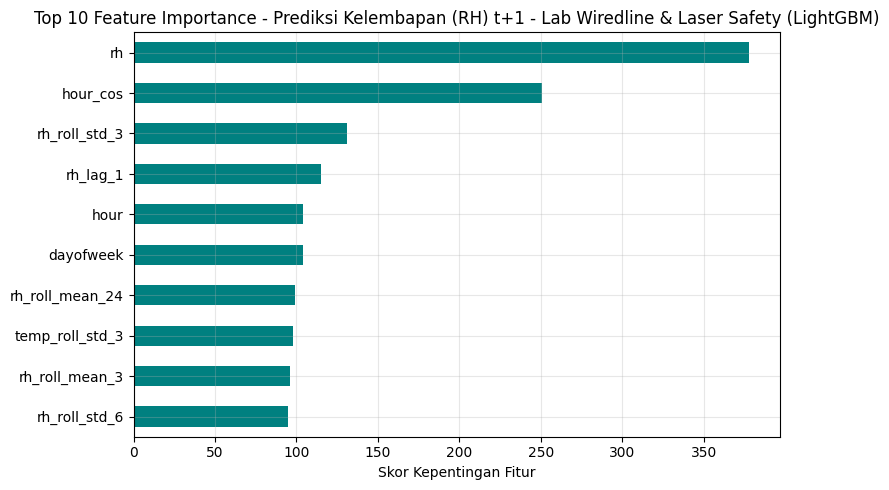


--- SHAP Summary Plot (Global) : Prediksi Kelembapan (RH) t+1 - Lab Wiredline & Laser Safety (LightGBM) ---


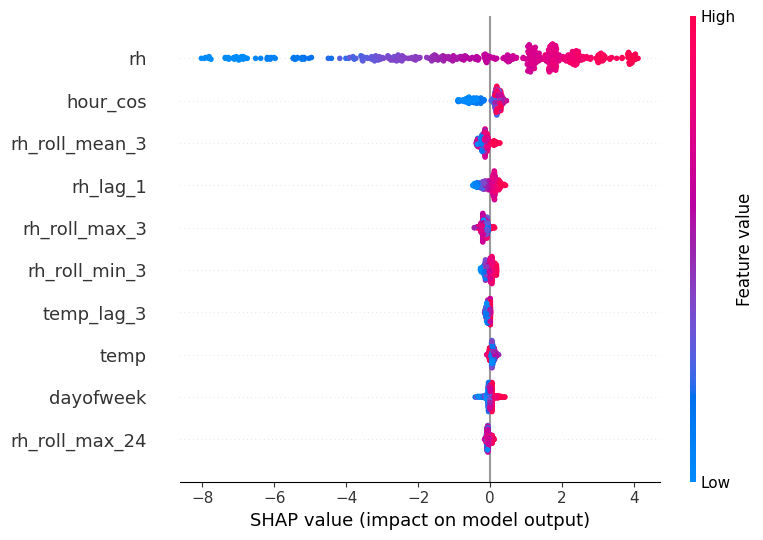


--- SHAP Waterfall Plot (Lokal - Observasi Uji ke-0) : Prediksi Kelembapan (RH) t+1 - Lab Wiredline & Laser Safety (LightGBM) ---


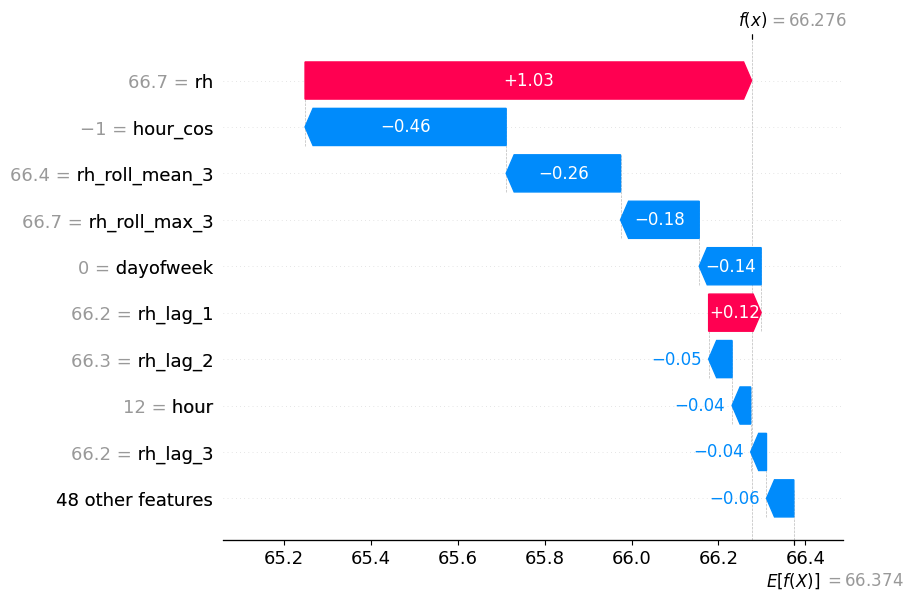

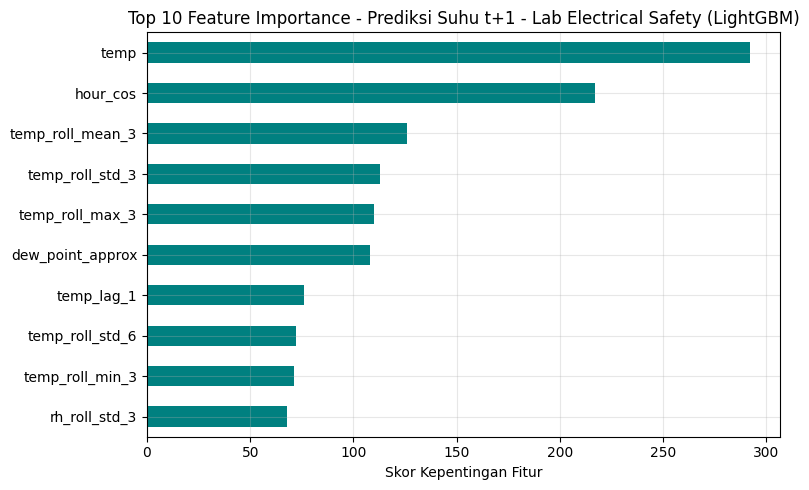


--- SHAP Summary Plot (Global) : Prediksi Suhu t+1 - Lab Electrical Safety (LightGBM) ---


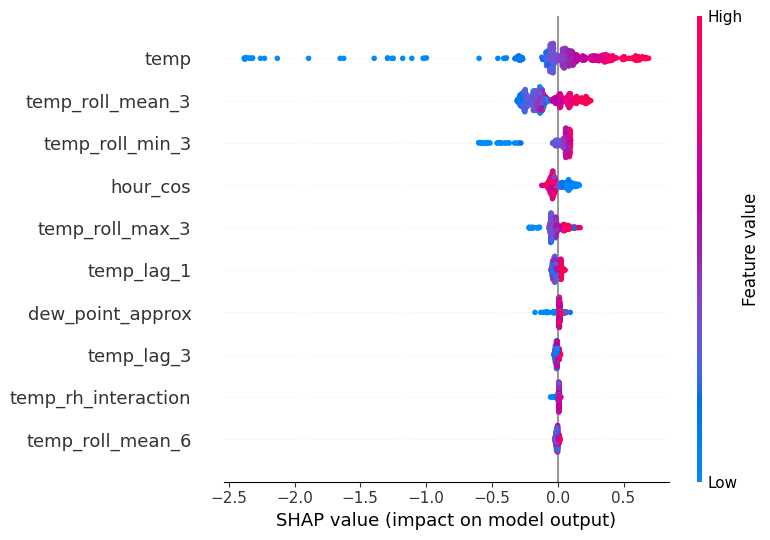


--- SHAP Waterfall Plot (Lokal - Observasi Uji ke-0) : Prediksi Suhu t+1 - Lab Electrical Safety (LightGBM) ---


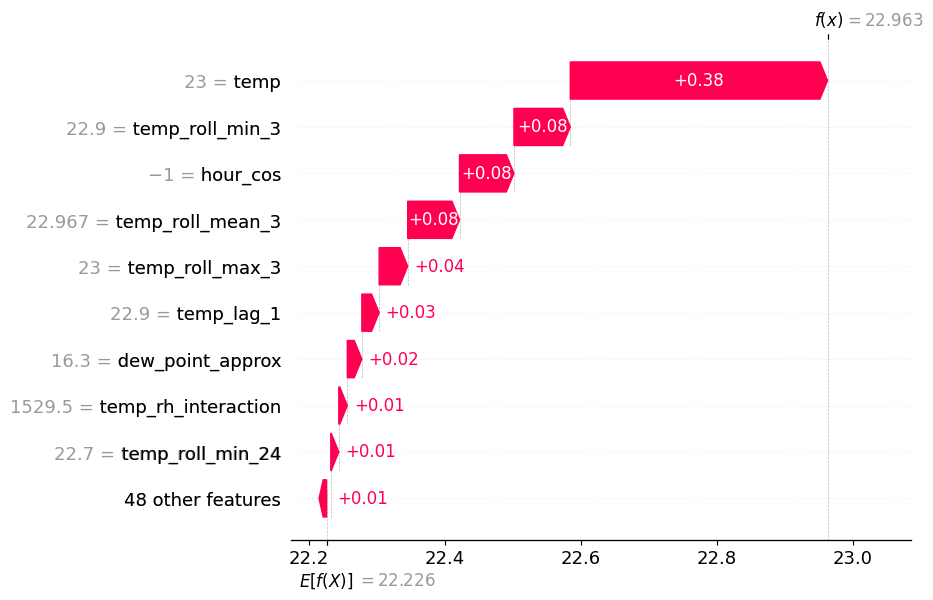

In [6]:
# ==============================================================================
# SEL 6: BLOK 4 (RM 4) - INTERPRETASI MODEL DENGAN FEATURE IMPORTANCE & SHAP
# ==============================================================================
def analyze_shap_and_importance(model, X_test_df, feature_names, title_label):
    # 1. Tree Feature Importance (Top 10 Fitur)
    importances = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=True)
    plt.figure(figsize=(8, 5))
    importances.tail(10).plot(kind='barh', color='teal')
    plt.title(f'Top 10 Feature Importance - {title_label}')
    plt.xlabel('Skor Kepentingan Fitur')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # 2. SHAP Global Interpretation (Summary Plot)
    explainer = shap.TreeExplainer(model)
    X_sample  = X_test_df[feature_names].iloc[:500] # Sampel uji untuk percepatan visualisasi
    shap_vals = explainer(X_sample)

    print(f"\n--- SHAP Summary Plot (Global) : {title_label} ---")
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_vals, X_sample, max_display=10, show=True)

    # 3. SHAP Local Interpretation (Waterfall Plot pada 1 kasus sampel)
    print(f"\n--- SHAP Waterfall Plot (Lokal - Observasi Uji ke-0) : {title_label} ---")
    plt.figure(figsize=(8, 5))
    shap.plots.waterfall(shap_vals[0], max_display=10, show=True)

# Jalankan analisis SHAP untuk model LightGBM di kedua ruangan (Horizon t+1)
model_wire_rh = art_S1['S1 (Per-room Wiredline)_LightGBM_rh_h1']
analyze_shap_and_importance(
    model_wire_rh, wire_test, FEATURE_COLS,
    title_label="Prediksi Kelembapan (RH) t+1 - Lab Wiredline & Laser Safety (LightGBM)"
)

model_elec_temp = art_S2['S2 (Per-room Electrical)_LightGBM_temp_h1']
analyze_shap_and_importance(
    model_elec_temp, elec_test, FEATURE_COLS,
    title_label="Prediksi Suhu t+1 - Lab Electrical Safety (LightGBM)"
)

# **Sel 7: Visualisasi Komparasi Antar-Horizon & Generalisasi Antar-Ruang (RM 3 & RM 5)**
Sel ini membuat visualisasi grafik komparatif penurunan akurasi seiring bertambahnya horizon ($t+1, t+3, t+6$) dan perbandingan skenario generalisasi (Per-room vs Cross-room vs Pooled) untuk dimasukkan langsung ke dalam Bab 4 Naskah Tesis.

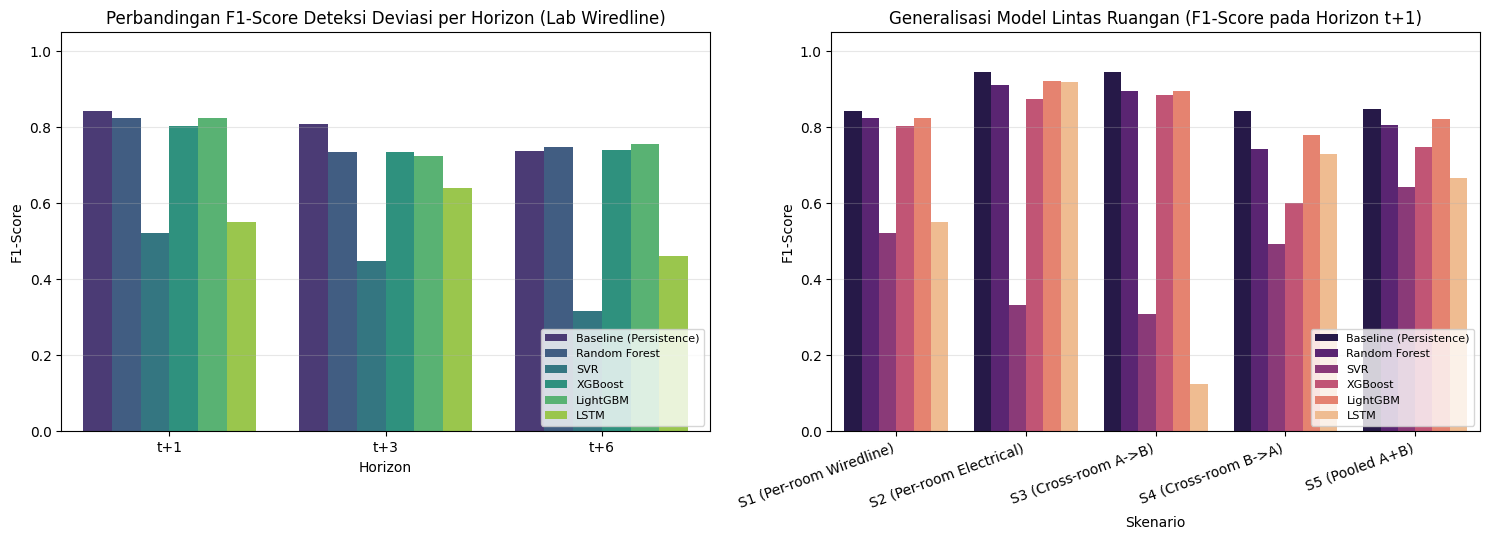

In [7]:
# ==============================================================================
# SEL 7: VISUALISASI TRADE-OFF MULTI-HORIZON & GENERALISASI LINTAS RUANG
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Plot Perbandingan F1-Score Antar Model pada Berbagai Horizon (S1 - Wiredline)
sns.barplot(
    data=res_S1, x='Horizon', y='F1', hue='Model', ax=axes[0], palette='viridis'
)
axes[0].set_title('Perbandingan F1-Score Deteksi Deviasi per Horizon (Lab Wiredline)')
axes[0].set_ylabel('F1-Score')
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc='lower right', fontsize=8)
axes[0].grid(True, axis='y', alpha=0.3)

# 2. Plot Evaluasi Generalisasi Lintas Ruangan (S1 s.d. S5 pada Horizon t+1)
df_h1 = df_all_results[df_all_results['Horizon'] == 't+1']
sns.barplot(
    data=df_h1, x='Skenario', y='F1', hue='Model', ax=axes[1], palette='magma'
)
axes[1].set_title('Generalisasi Model Lintas Ruangan (F1-Score pada Horizon t+1)')
axes[1].set_ylabel('F1-Score')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=20, ha='right')
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc='lower right', fontsize=8)
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('komparasi_multi_horizon_dan_generalisasi.png', dpi=150)
plt.show()